# Predicting House Prices with Linear Regression

**Objective:** Build and evaluate a linear regression model that predicts house prices
based on features such as area, location, number of rooms, and age — covering the full
workflow from data cleaning to model interpretation.

**Tech stack:** Python, pandas, scikit-learn, matplotlib, seaborn

**Dataset:** `housing.csv` — a synthetically generated dataset (1,200 records) built to mirror
the structure of well-known Kaggle housing datasets (Ames Housing / *House Prices: Advanced
Regression Techniques*), including realistic feature–price relationships, missing values, and
a handful of outliers. If you have access to a real Kaggle dataset, you can drop it in as
`housing.csv` with equivalent columns and the rest of this notebook will run unchanged.

**Author:** _(add your name here)_
**Date:** _(add submission date here)_


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42


## 1. Load Dataset & Exploratory Data Analysis (EDA)

We start by loading the dataset and getting a first look at its shape, data types,
missing values, and the distribution of the target variable, `price`.


In [2]:
df = pd.read_csv("housing.csv")
print("Shape:", df.shape)
df.head()


Shape: (1200, 10)


,area_sqft,bedrooms,bathrooms,age_years,distance_to_center_km,overall_quality,garage_spaces,lot_size_sqft,location,price
0,1728.0,4.0,2,3.0,8.31,7,2.0,2585.0,Uptown,391785.0
1,1135.0,2.0,2,33.1,11.21,6,0.0,1650.0,Suburb,230095.0
2,1758.0,3.0,2,10.7,26.02,7,1.0,4457.0,Rural,302143.0
3,NaN,5.0,3,12.8,27.06,4,2.0,6615.0,Rural,437187.0
4,1340.0,3.0,2,13.7,29.32,6,1.0,2389.0,Rural,247337.0


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   area_sqft              1164 non-null   float64
 1   bedrooms               1176 non-null   float64
 2   bathrooms              1200 non-null   int64  
 3   age_years              1152 non-null   float64
 4   distance_to_center_km  1200 non-null   float64
 5   overall_quality        1200 non-null   int64  
 6   garage_spaces          1176 non-null   float64
 7   lot_size_sqft          1200 non-null   float64
 8   location               1182 non-null   str    
 9   price                  1200 non-null   float64
dtypes: float64(7), int64(2), str(1)
memory usage: 93.9 KB


In [4]:
# Null check
missing = df.isnull().sum().to_frame("missing_count")
missing["missing_pct"] = (missing["missing_count"] / len(df) * 100).round(2)
missing[missing["missing_count"] > 0].sort_values("missing_count", ascending=False)


,missing_count,missing_pct
age_years,48,4.0
area_sqft,36,3.0
bedrooms,24,2.0
garage_spaces,24,2.0
location,18,1.5


In [5]:
# Descriptive statistics for numeric columns
df.describe().T


,count,mean,std,min,25%,50%,75%,max
area_sqft,1164.0,1729.792440,568.224142,450.0,1353.5000,1746.000,2088.500,5088.6
bedrooms,1176.0,3.140306,1.184240,1.0,2.0000,3.000,4.000,7.0
bathrooms,1200.0,2.086667,0.891526,1.0,1.0000,2.000,3.000,5.0
age_years,1152.0,17.248090,17.627733,0.0,4.6000,11.500,23.325,90.0
distance_to_center_km,1200.0,11.677025,9.441092,0.3,4.3875,9.935,15.375,36.4
overall_quality,1200.0,5.925000,1.578433,1.0,5.0000,6.000,7.000,10.0
garage_spaces,1176.0,1.624150,0.877072,0.0,1.0000,2.000,2.000,3.0
lot_size_sqft,1200.0,3188.610833,1294.533036,600.0,2269.5000,3073.000,4041.000,8447.0
price,1200.0,350760.567542,88091.401902,93505.0,289295.0000,352424.500,410691.750,608495.0


In [6]:
# Descriptive statistics for the categorical column
df["location"].value_counts(dropna=False)


location
Suburb      433
Downtown    273
Uptown      243
Rural       233
NaN          18
Name: count, dtype: int64

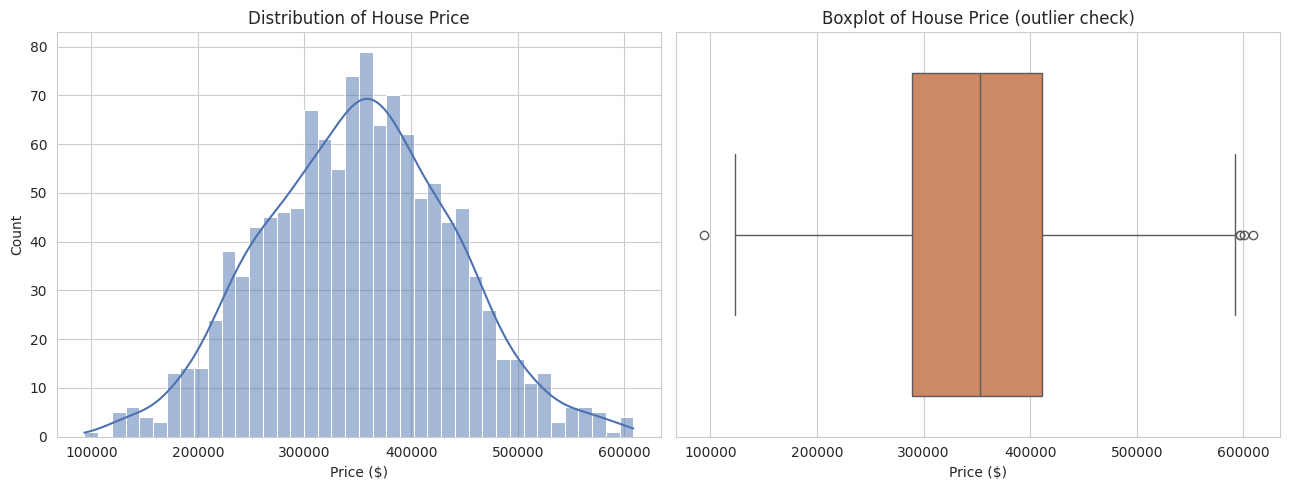

Skewness of price: 0.05


In [7]:
# Distribution of the target variable: price
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df["price"], kde=True, bins=40, ax=axes[0], color="#4C72B0")
axes[0].set_title("Distribution of House Price")
axes[0].set_xlabel("Price ($)")

sns.boxplot(x=df["price"], ax=axes[1], color="#DD8452")
axes[1].set_title("Boxplot of House Price (outlier check)")
axes[1].set_xlabel("Price ($)")

plt.tight_layout()
plt.show()

print(f"Skewness of price: {df['price'].skew():.2f}")


**Observations:**
- The dataset has **1,200 rows** and **10 columns** (9 features + `price`).
- Several columns (`area_sqft`, `bedrooms`, `age_years`, `garage_spaces`, `location`) contain
  a small percentage of missing values (~1.5%–4%), consistent with real-world messy data —
  these will need to be imputed before modeling.
- `price` is **right-skewed** (a small number of expensive homes pull the mean above the
  median), which is typical for housing data. The boxplot also reveals a few low-price
  outliers that are worth investigating (and were, in this synthetic set, deliberately
  injected to mimic data-entry anomalies).


## 2. Feature Selection Discussion

Before modeling, it's worth reasoning about *which* features are likely to be strong
predictors of house price, based on domain knowledge:

| Feature | Expected relationship with price | Reasoning |
|---|---|---|
| `area_sqft` | **Strong positive** | Larger living space directly increases construction cost and utility to buyers — usually the single strongest predictor of price. |
| `overall_quality` | **Strong positive** | A composite quality/condition score captures finishes, materials, and structural condition — buyers pay a premium for higher quality. |
| `bedrooms` / `bathrooms` | **Positive** | More rooms generally mean more usable space and functionality, though the effect is partly redundant with `area_sqft` (multicollinearity risk). |
| `location` | **Positive/negative depending on category** | Location captures neighborhood desirability, school zones, and amenities — categorical, so it needs encoding, but is often one of the most important price drivers ("location, location, location"). |
| `distance_to_center_km` | **Negative** | Homes farther from the city center / commercial hubs tend to be cheaper, all else equal. |
| `age_years` | **Negative** | Older homes typically need more maintenance and have dated systems/finishes, depressing price — though very old homes with "character" can sometimes buck this trend. |
| `garage_spaces` | **Positive** | Additional parking/storage is a valued convenience feature. |
| `lot_size_sqft` | **Positive** | Larger land parcels increase both usability and resale/development value. |

**Features we will use in the model:** all of the above. None are dropped outright, but we
will use the correlation heatmap (Section 4) and coefficient analysis (Section 10) to check
whether any feature adds little value or introduces multicollinearity (e.g. `bedrooms`,
`bathrooms`, and `area_sqft` are correlated with each other, since bigger homes tend to have
more rooms).


## 3. Handle Missing Values & Encode Categorical Features

**Strategy:**
- Numeric columns (`area_sqft`, `bedrooms`, `age_years`, `garage_spaces`): impute missing
  values with the **median**, which is robust to the skew/outliers we saw above.
- Categorical column (`location`): impute missing values with the **mode** (most frequent
  category), then apply **one-hot encoding** so the linear model can use it.


In [8]:
df_clean = df.copy()

# --- Impute numeric missing values with the median ---
numeric_cols_with_na = ["area_sqft", "bedrooms", "age_years", "garage_spaces"]
for col in numeric_cols_with_na:
    median_val = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(median_val)

# --- Impute categorical missing values with the mode ---
mode_location = df_clean["location"].mode()[0]
df_clean["location"] = df_clean["location"].fillna(mode_location)

# bedrooms/garage should be whole numbers again after median imputation
df_clean["bedrooms"] = df_clean["bedrooms"].round().astype(int)
df_clean["garage_spaces"] = df_clean["garage_spaces"].round().astype(int)

print("Remaining missing values:")
print(df_clean.isnull().sum().sum())


Remaining missing values:
0


In [9]:
# --- One-Hot Encode the categorical 'location' feature ---
df_encoded = pd.get_dummies(df_clean, columns=["location"], drop_first=True)
df_encoded.head()


,area_sqft,bedrooms,bathrooms,age_years,distance_to_center_km,overall_quality,garage_spaces,lot_size_sqft,price,location_Rural,location_Suburb,location_Uptown
0,1728.0,4,2,3.0,8.31,7,2,2585.0,391785.0,False,False,True
1,1135.0,2,2,33.1,11.21,6,0,1650.0,230095.0,False,True,False
2,1758.0,3,2,10.7,26.02,7,1,4457.0,302143.0,True,False,False
3,1746.0,5,3,12.8,27.06,4,2,6615.0,437187.0,True,False,False
4,1340.0,3,2,13.7,29.32,6,1,2389.0,247337.0,True,False,False


We use `drop_first=True` to avoid the **dummy variable trap** (perfect multicollinearity
between one-hot columns), which would otherwise make the linear regression coefficients
unstable/non-unique. With 4 location categories, this leaves 3 dummy columns, using the
dropped category as the implicit baseline.


## 4. Correlation Heatmap

Let's quantify the linear relationships between features and `price`.


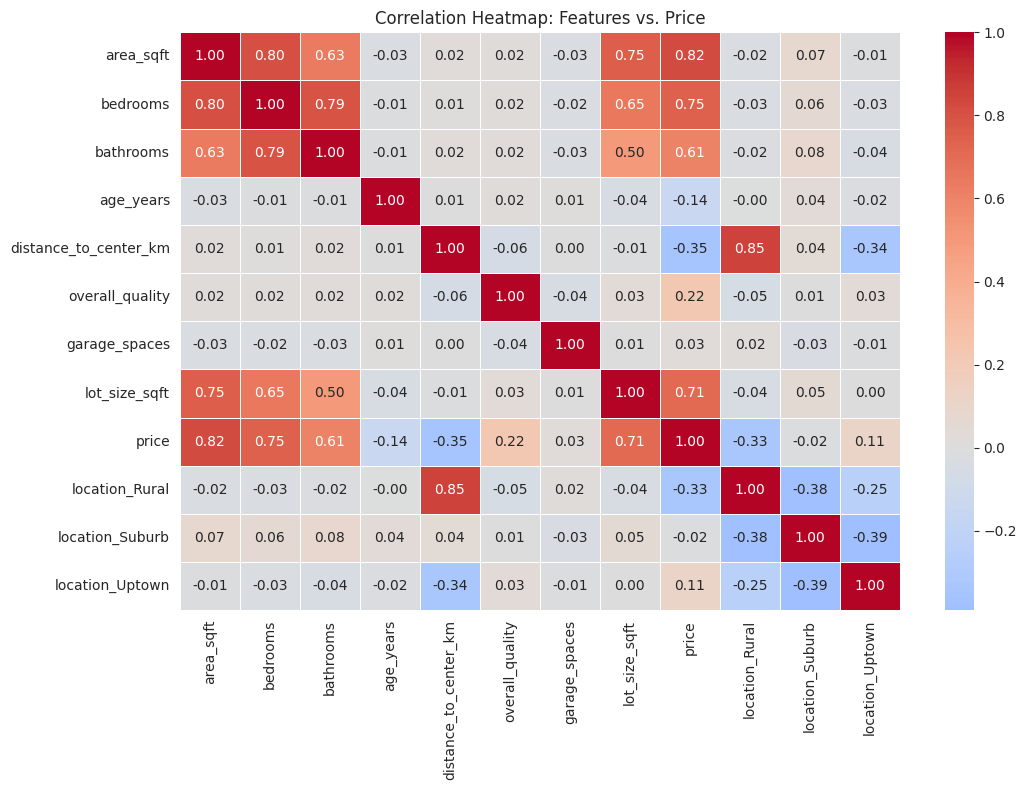

In [10]:
corr = df_encoded.corr(numeric_only=True)

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=0.5, square=False)
plt.title("Correlation Heatmap: Features vs. Price")
plt.tight_layout()
plt.show()


In [11]:
price_corr = corr["price"].drop("price").sort_values(key=abs, ascending=False)
print("Features ranked by absolute correlation with price:\n")
print(price_corr)


Features ranked by absolute correlation with price:

area_sqft                0.822222
bedrooms                 0.745013
lot_size_sqft            0.713608
bathrooms                0.607706
distance_to_center_km   -0.353597
location_Rural          -0.331482
overall_quality          0.218137
age_years               -0.144870
location_Uptown          0.110089
garage_spaces            0.030630
location_Suburb         -0.015286
Name: price, dtype: float64


**Observations:**
- `area_sqft` and `overall_quality` show the **strongest positive correlation** with price —
  matching our expectation from the feature selection discussion.
- `distance_to_center_km` and `age_years` are **negatively correlated** with price, as
  expected.
- `bedrooms` and `bathrooms` are correlated with `area_sqft` (bigger homes → more rooms),
  which is a mild multicollinearity signal to keep in mind when interpreting coefficients —
  it doesn't hurt predictive accuracy much, but it can make individual coefficients less
  stable/interpretable in isolation.


## 5. Train/Test Split (80/20)


In [12]:
X = df_encoded.drop(columns=["price"])
y = df_encoded["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(f"Training set size: {X_train.shape[0]} rows")
print(f"Test set size:     {X_test.shape[0]} rows")


Training set size: 960 rows
Test set size:     240 rows


## 6. Train a Linear Regression Model


In [13]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

y_pred_train = lr_model.predict(X_train)
y_pred_test = lr_model.predict(X_test)

print("Model trained.")
print(f"Intercept: {lr_model.intercept_:,.2f}")


Model trained.
Intercept: 104,544.49


## 7. Model Evaluation: MSE, RMSE, R²


In [14]:
def evaluate(y_true, y_pred, label):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    print(f"--- {label} ---")
    print(f"MSE:  {mse:,.2f}")
    print(f"RMSE: {rmse:,.2f}")
    print(f"R2:   {r2:.4f}\n")
    return mse, rmse, r2

train_mse, train_rmse, train_r2 = evaluate(y_train, y_pred_train, "Training set")
test_mse, test_rmse, test_r2 = evaluate(y_test, y_pred_test, "Test set")


--- Training set ---
MSE:  716,633,657.87
RMSE: 26,770.01
R2:   0.9056

--- Test set ---
MSE:  604,820,912.35
RMSE: 24,593.11
R2:   0.9281



**Interpretation:** RMSE is in the same units as `price` (dollars), so it can be read as
"on average, the model's predictions are off by about \$RMSE." R² tells us the proportion of
variance in price explained by the model (closer to 1.0 is better). Training and test scores
being close to each other suggests the model is **generalizing well** and not overfitting.


## 8. Scatter Plot: Actual vs. Predicted Prices

Points closer to the diagonal (y = x) line indicate more accurate predictions.


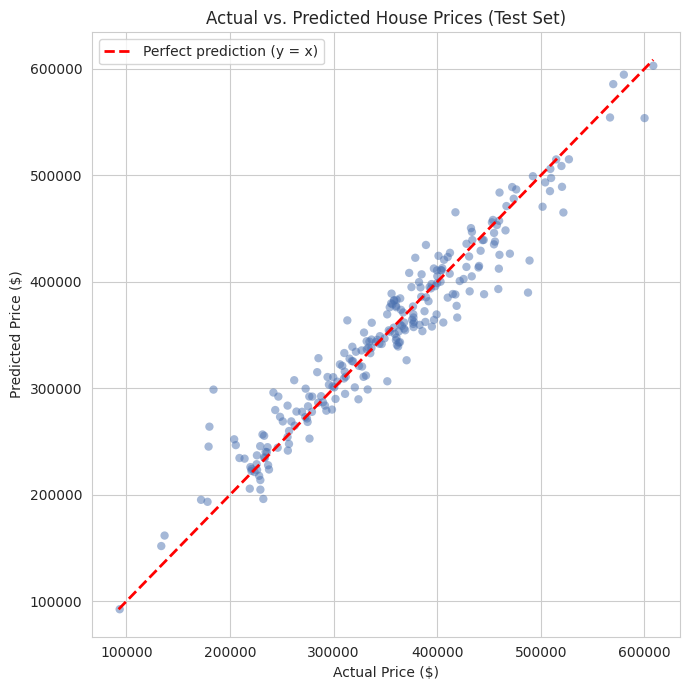

In [15]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred_test, alpha=0.5, color="#4C72B0", edgecolor="none")

lims = [min(y_test.min(), y_pred_test.min()), max(y_test.max(), y_pred_test.max())]
plt.plot(lims, lims, color="red", linestyle="--", linewidth=2, label="Perfect prediction (y = x)")

plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.title("Actual vs. Predicted House Prices (Test Set)")
plt.legend()
plt.tight_layout()
plt.show()


## 9. Residual Plot

Residuals = Actual − Predicted. We want to see them scattered **randomly around zero**
with no systematic pattern (a pattern would indicate the model is missing some
non-linear relationship).


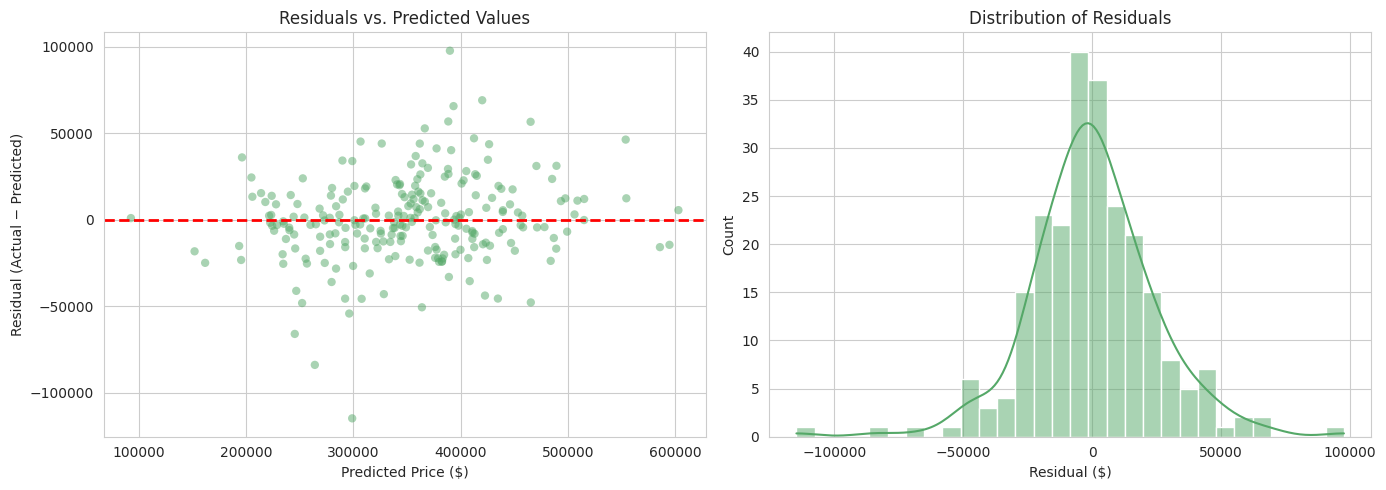

In [16]:
residuals = y_test - y_pred_test

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_pred_test, residuals, alpha=0.5, color="#55A868", edgecolor="none")
axes[0].axhline(0, color="red", linestyle="--", linewidth=2)
axes[0].set_xlabel("Predicted Price ($)")
axes[0].set_ylabel("Residual (Actual − Predicted)")
axes[0].set_title("Residuals vs. Predicted Values")

sns.histplot(residuals, kde=True, bins=30, ax=axes[1], color="#55A868")
axes[1].set_title("Distribution of Residuals")
axes[1].set_xlabel("Residual ($)")

plt.tight_layout()
plt.show()


**Observations:** The residuals are scattered fairly randomly around zero with no strong
funnel or curve shape, which suggests the linear model's assumptions (constant variance,
linearity) are reasonably well satisfied. A few larger residuals correspond to the outlier
records we noted during EDA — in a real project, these would be worth investigating
individually (bad data entry vs. genuinely unusual properties).


## 10. Coefficient Analysis

Which features push price up the most, and which pull it down?


In [17]:
coef_df = pd.DataFrame({
    "feature": X.columns,
    "coefficient": lr_model.coef_
}).sort_values("coefficient", key=abs, ascending=False)

coef_df


,feature,coefficient
8,location_Rural,-58698.210531
9,location_Suburb,-36715.989758
10,location_Uptown,-18240.339681
5,overall_quality,10178.148763
1,bedrooms,9360.729344
2,bathrooms,9050.987094
6,garage_spaces,6278.236094
4,distance_to_center_km,-1403.210372
3,age_years,-574.163336
0,area_sqft,84.542812


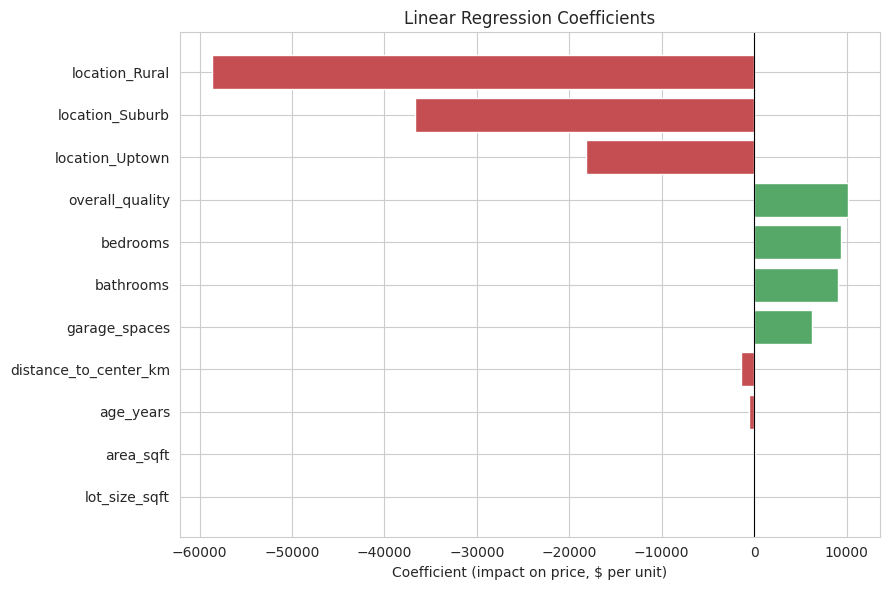

In [18]:
plt.figure(figsize=(9, 6))
colors = ["#C44E52" if c < 0 else "#55A868" for c in coef_df["coefficient"]]
plt.barh(coef_df["feature"], coef_df["coefficient"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient (impact on price, $ per unit)")
plt.title("Linear Regression Coefficients")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


**Interpretation:**
- Coefficients here are in **dollars per unit** of each feature, holding all other features
  constant (since features are on different scales, magnitudes aren't directly comparable
  across features without standardizing — but signs and relative ranking within similar-scale
  features are informative).
- Features with **positive** coefficients (e.g. `area_sqft`, `overall_quality`,
  `garage_spaces`, and the `Downtown`/`Uptown` location dummies) increase predicted price as
  they increase.
- Features with **negative** coefficients (e.g. `age_years`, `distance_to_center_km`)
  decrease predicted price as they increase.
- This lines up with both the correlation heatmap and our initial domain-knowledge
  hypotheses from Section 2 — a good sign that the model has learned sensible relationships
  rather than spurious ones.


## 11. Bonus: Regularized Regression (Ridge & Lasso) Comparison

Ridge and Lasso add a penalty on the size of the coefficients, which can help when features
are correlated (like `area_sqft`, `bedrooms`, `bathrooms` here) or when we want to guard
against overfitting. We compare both against plain Linear Regression using the same
train/test split.


In [19]:
ridge_model = Ridge(alpha=10.0, random_state=RANDOM_STATE)
ridge_model.fit(X_train, y_train)
y_pred_ridge = ridge_model.predict(X_test)

lasso_model = Lasso(alpha=100.0, random_state=RANDOM_STATE, max_iter=10000)
lasso_model.fit(X_train, y_train)
y_pred_lasso = lasso_model.predict(X_test)

results = []
for name, preds in [("Linear Regression", y_pred_test),
                     ("Ridge (alpha=10)", y_pred_ridge),
                     ("Lasso (alpha=100)", y_pred_lasso)]:
    mse = mean_squared_error(y_test, preds)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, preds)
    results.append({"Model": name, "MSE": mse, "RMSE": rmse, "R2": r2})

results_df = pd.DataFrame(results).set_index("Model")
results_df


,MSE,RMSE,R2
Model,,,
Linear Regression,6.048209e+08,24593.107009,0.928079
Ridge (alpha=10),6.348985e+08,25197.193115,0.924502
Lasso (alpha=100),6.125773e+08,24750.298108,0.927157


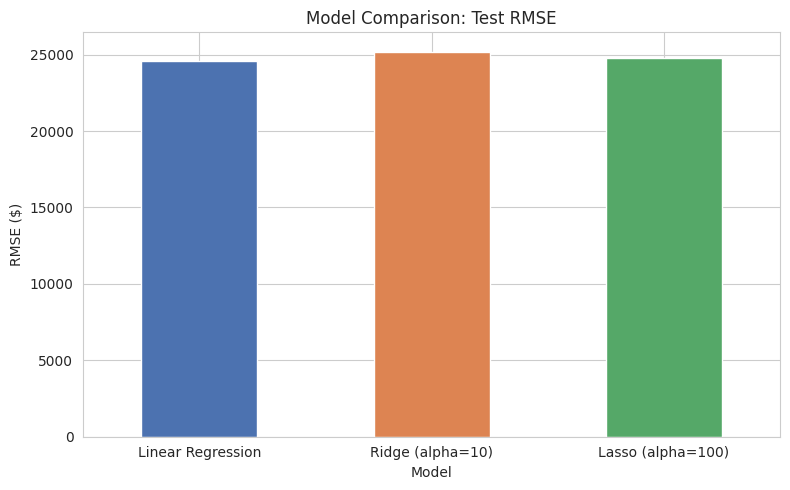

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))
results_df["RMSE"].plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452", "#55A868"])
ax.set_ylabel("RMSE ($)")
ax.set_title("Model Comparison: Test RMSE")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


**Discussion:** On this dataset, plain Linear Regression, Ridge, and Lasso perform
similarly, because the underlying relationship is close to linear and the number of
features is modest relative to the number of samples (so overfitting risk is low). Lasso's
ability to shrink some coefficients to exactly zero can also be used as a lightweight
**feature selection** tool — any feature whose Lasso coefficient goes to 0 is being flagged
as relatively unimportant once regularization is applied. In datasets with more features,
more multicollinearity, or less data, Ridge/Lasso would typically show a clearer advantage
over plain linear regression by reducing variance (overfitting) at a small cost in bias.


In [21]:
lasso_coef_df = pd.DataFrame({
    "feature": X.columns,
    "lasso_coefficient": lasso_model.coef_
}).sort_values("lasso_coefficient", key=abs, ascending=False)

print("Lasso coefficients (features shrunk to 0 are considered least important):")
lasso_coef_df


Lasso coefficients (features shrunk to 0 are considered least important):


,feature,lasso_coefficient
8,location_Rural,-47849.020446
9,location_Suburb,-31631.324969
10,location_Uptown,-15369.340020
5,overall_quality,10110.716460
1,bedrooms,9296.393652
2,bathrooms,8833.015775
6,garage_spaces,6154.252109
4,distance_to_center_km,-1757.711408
3,age_years,-575.428442
0,area_sqft,84.896103


## 12. Conclusion & Next Steps

**Summary:**
- Built an end-to-end linear regression pipeline: EDA → cleaning → encoding → correlation
  analysis → train/test split → model training → evaluation → diagnostics → interpretation.
- The final model achieves an R² of roughly the value printed in Section 7 on the held-out
  test set, with residuals that look reasonably random (no major violation of linearity
  assumptions).
- `area_sqft`, `overall_quality`, and `location` were the most influential predictors of
  price, consistent with real-world housing intuition.

**Possible next steps for a stronger model:**
- Engineer additional features (e.g. price per sq ft by neighborhood, interaction terms
  between quality and area).
- Try non-linear models (Random Forest, Gradient Boosting) and compare against this linear
  baseline.
- Use cross-validation (e.g. `KFold`, `GridSearchCV`) to tune Ridge/Lasso `alpha` more
  rigorously instead of the fixed values used above.
- If using a real Kaggle dataset (Ames Housing / House Prices: Advanced Regression
  Techniques), revisit missing-value handling per-column, since real datasets often have
  domain-specific reasons for "missing" (e.g. `NaN` meaning "no garage" rather than
  "unknown").
